# Full-volume single-step TGV quantitative susceptibility mapping

## 1. Problem

Recover the signed scalar susceptibility of a real human brain from one wrapped gradient-echo phase volume. The selected benchmark contains **160 x 160 x 160 voxels**, with 933,481 brain-support voxels. The inverse calculation also estimates a phase-discrepancy potential. It is a coupled three-dimensional PDE/variational problem, rather than Fourier division or a single-slice surrogate.

The scientific question is whether the published single-step TGV formulation can reconstruct recognizable susceptibility contrast while incorporating phase wrapping, harmonic background removal and ill-conditioned dipole inversion in one optimization. The human measurements are imperfect: susceptibility anisotropy and transmit-phase components do not obey a perfectly isotropic scalar dipole model. Numerical reproduction, physical constraint satisfaction and agreement with independent multi-orientation measurements are therefore evaluated separately.

The public output consists of `reconstruction` in ppm and `residual_phase` in radians, both batch-first `(1,160,160,160)`, real float64, zero outside the supplied mask. The latter is an auxiliary discrepancy potential, not an estimated background phase. A standard-method comparison cannot establish biological ground truth.


## 2. Data

These are actual human measurements from the **2016 QSM Reconstruction Challenge**, acquired using a 15-fold accelerated Wave-CAIPI 3D gradient-echo sequence. We retain the complete author-released volume without synthetic noise, interpolation, target-based calibration or slice reduction.

The author-hosted source is [the original challenge archive](https://www.neuroimaging.at/media/qsm/20170327_qsm2016_recon_challenge.zip), SHA256 `2bc4b345c16d198b65e443df41cfab1f52fc6e0bc75483777284471566fb6d36`. Its `data/phs_wrap.mat`, `magn.mat`, `msk.mat`, `chi_cosmos.mat` and `chi_33.mat` are byte-identical to the files at the independently remotely verified data revision `ab218740e2ed9c218a4d009ed58d3ae80229a349`. Complete file hashes and original URLs are in `test/validation.md`. Conversion to NPZ changes containers only; the original values and dtypes remain unchanged.

| Public key | Shape | Dtype | Meaning and unit |
|---|---|---|---|
| phase | (1,160,160,160) | float64 | Original wrapped phase, rad |
| magnitude | (1,160,160,160) | float32 | Measured magnitude, arbitrary acquisition units |
| mask | (1,160,160,160) | bool | Original five-voxel-peeled brain support, unitless |

| Acquisition parameter | Value | Unit / convention |
|---|---|---|
| Voxel pitch | (1.0625,1.0625,1.0714285714285714) | mm, axes x,y,z |
| Main field | 2.89362 | T, nominally 3 T |
| Echo time | 0.025 | s |
| Proton frequency ratio | 42.58 | MHz/T, angular factor is 2*pi |
| Field direction | (0,0,1) | acquisition coordinates |
| Phase | [-pi,pi] | rad, supplied sign retained |
| Boundary | zero output outside brain | source finite-difference boundary convention |

The exact B0 and TE are justified by a separate identity check: the original complex acquisition paired with that protocol has a voxelwise phase matching this raw volume within 1.2e-7 rad. They were not fitted to a susceptibility target.

Private comparison arrays include **COSMOS from 12 orientations** and the **STI chi33 component used as the challenge's official reference**. These are independently reconstructed measurements; their physical meanings differ, and neither is relabeled simulated or exact biological truth. Magnitude is reviewed here but is not used for a morphology prior by the selected single-step method.


phase public batch shape: (1, 160, 160, 160) dtype: float64
magnitude public batch shape: (1, 160, 160, 160) dtype: float32
mask public batch shape: (1, 160, 160, 160) dtype: bool
Brain voxels: 933481 PDE interior: 887715
Backend: 2.9.1+cu128 12.8 NVIDIA GeForce RTX 4080 SUPER


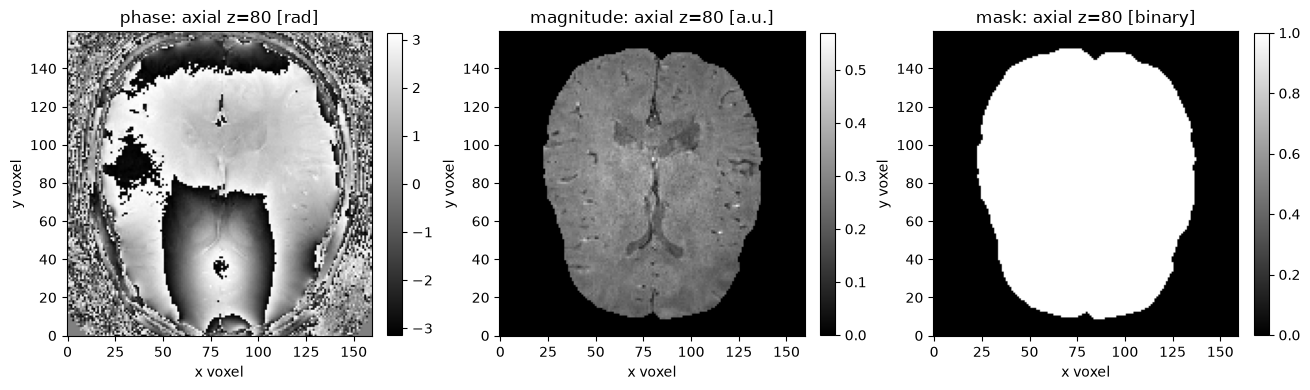

In [1]:
%matplotlib inline
from pathlib import Path
import os, sys, time, json, subprocess
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
TASK = Path.cwd() if (Path.cwd()/"data/raw_data.npz").exists() else Path.cwd().parent
os.chdir(TASK)
sys.path.insert(0, str(TASK))
from src.preprocessing import load_data, SPACING, PHASE_PER_PPM, crop_slices
from src.solvers import reconstruct, DEFAULT_LAMBDA, DEFAULT_RATIO
from src.physics_model import interior_mask, wrapped_laplacian, laplacian, wave_operator
from src.visualization import (metrics, observation_metrics, observation_figure,
    reconstruction_figure, method_comparison_figure)
observations = load_data()
for key, array in observations.items():
    print(key, "public batch shape:", (1, *array.shape), "dtype:", array.dtype)
print("Brain voxels:", observations['mask'].sum(), "PDE interior:", interior_mask(observations['mask']).sum())
print("Backend:", torch.__version__, torch.version.cuda, torch.cuda.get_device_name(0))
observation_figure(observations)
plt.show()

## 3. Physics

Let $\chi$ be susceptibility in ppm, $\phi$ wrapped phase in rad, and $s=2\pi\gamma B_0T_E$ in rad/ppm. For a nonzero frequency vector $k$, the dipole transfer is


$$
D(k)=\frac13-\frac{k_z^2}{k_x^2+k_y^2+k_z^2},\qquad
\phi=\operatorname{wrap}(sD\chi+b+\epsilon).
$$


The background phase $b$ is harmonic only for magnetic sources outside the modeled region; noise $\epsilon$, tissue anisotropy and nonharmonic transmit phase create model discrepancy. Set $L=\partial_{xx}+\partial_{yy}+\partial_{zz}$ and $W=\partial_{zz}-L/3$. Their Fourier symbols give $LD=-W$. The main-field direction and this sign are tested independently on a transverse cosine mode.

Wrapped first differences are reduced to the principal interval before a backward divergence. This yields a discrete $L_{\mathrm{wrap}}\phi$ without substituting the Laplacian of an already processed tissue-field image. Each derivative uses its actual mm pitch. An added harmonic phase has zero interior Laplacian, explaining the background-removal mechanism.

The source works with phase-unit susceptibility $x=s\chi$ and discrepancy potential $\eta$ in rad:


$$
L\eta-Wx-L_{\mathrm{wrap}}\phi=0.
$$


Both primal unknowns are zero outside the brain mask $M$. The PDE rows and derivative penalties use the six-neighbor interior $M_i$. Array faces remain zero, and the source's crop extends the mask bounding box by two voxels; no brain observations are dropped. The source preserves a zero brain-mean gauge from zero initialization, which fixes the physically unobservable susceptibility constant. No fitted shift, scale, magnitude conversion or image registration is applied in the comparisons.


In [2]:
print("Phase per ppm s =", PHASE_PER_PPM, "rad/ppm")
print("Source crop:", crop_slices(observations['mask']))
print("Physical grid [mm]:", SPACING)
print("Laplacian RMS over PDE support [rad/mm^2]:", np.sqrt(np.mean(wrapped_laplacian(observations['phase'], SPACING)[interior_mask(observations['mask'])]**2)))

Phase per ppm s = 19.353834886683178 rad/ppm
Source crop: (slice(18, 143, None), slice(7, 157, None), slice(11, 137, None))
Physical grid [mm]: (1.0625, 1.0625, 1.0714285714285714)


Laplacian RMS over PDE support [rad/mm^2]: 0.6229709096599797


## 4. Method

The implementation extracts the published single-step TGV method into local NumPy and PyTorch mathematics. The independent original numerical oracle is QSM.m revision `f22dc40d81495b37438fbf66f86c9281f8326813`, executed in Octave 8.4 with original C MEX operators. The released runtime imports none of that library.

For an auxiliary vector field $v$ in rad/mm, define the symmetric derivative $Ev=(\nabla v+\nabla v^T)/2$. The implemented convex problem is


$$
\min_{x,\eta,v}\frac12\|\eta\|_2^2
 +\lambda\sum_{M_i}\|\nabla x-v\|_2
 +r\lambda\sum_{M_i}\|Ev\|_{\mathrm F}
\quad\text{subject to}\quad
M_i(L\eta-Wx-L_{\mathrm{wrap}}\phi)=0.
$$


The sum of squares for $\eta$ uses the full primal mask. The symmetric tensor is stored in order xx,xy,xz,yy,yz,zz, with the off-diagonal entries counted twice in the Frobenius norm. No voxel-volume factor is required because the same fixed cell volume multiplies all objective terms.

**Parameter provenance.** The paper writes a full squared discrepancy term and gives physical-unit weights $(\alpha_1,\alpha_0)=(0.0015,0.0005)$. The source proximal factor $1/(1+\tau)$ instead implements a half-squared term. Under $x=s\chi$, $\eta=s\psi$ and $v=sw$, the squared term scales as $s^2$ and TGV as $s$. Dividing by $s^2$ shows that the source coefficient is therefore $\lambda=s\alpha_1/2$ and $r=\alpha_0/\alpha_1=1/3$. The code's original default ratio is 3, so that default and the paper-recommended pair are explicitly different configurations. The canonical pair was fixed from these equations before seeing its comparison metrics. Diagnostic regularization sweeps are retained privately, not used to call a fitted setting the default.

**Explicit inverse updates.** Let $\nu$ be the PDE dual variable, $p$ the three-component first-derivative dual variable, and $q$ the six-component symmetric-tensor dual variable. A bar denotes extrapolation and $P_a$ pointwise projection onto a Euclidean or Frobenius ball of radius $a$. With zero initialization, the iteration is


$$
\nu^+ = \nu+\sigma M_i(L\bar\eta-W\bar x-L_{\mathrm{wrap}}\phi),
\qquad p^+=P_\lambda[p+\sigma M_i(\nabla\bar x-\bar v)],
\qquad q^+=P_{r\lambda}[q+\sigma M_iE\bar v],
$$


$$
\eta^+=M\frac{\eta-\tau L\nu^+}{1+\tau},\qquad
x^+=M[x+\tau(\operatorname{div}p^++W\nu^+)],\qquad
v^+=M[v+\tau(p^++\operatorname{Div}q^+)].
$$


Here div is the negative adjoint of the forward gradient and Div is the negative Frobenius adjoint of the symmetric derivative. Extrapolation is $\bar u^+=2u^+-u$ for every primal variable $u$. The source chooses equal steps $\tau=\sigma=1/\sqrt{g^2+a^2}$, where $g=4\sum_jh_j^{-2}$ and $a=2(h_x^{-2}+h_y^{-2}+2h_z^{-2})$, with voxel pitch $h_j$ in mm. Every ten iterations it checks the change from the immediately previous single update: $\|\delta x\|/\|x\|<3\times10^{-4}$ and $\|\delta\eta\|/\|\eta\|<6\times10^{-4}$, with a cap of 5000 steps. The active benchmark executes this complete stopping path. TV uses the same data constraint and first-order weight but removes $v,q$ and the second-order penalty; it is also freshly reconstructed below.

**Investigated source discrepancy.** Original QSM.m incorrectly reuses the component-axis pitch for all three derivative directions in the tensor divergence. With unequal z pitch, an independent adjoint check gives 1.9643% relative error. A minimal correction restores derivative-axis pitches and reduces that check to 9.04e-16. The original run is preserved separately; the corrected C oracle and local code are independently compared. This is an identified correction, not a claim of unchanged-source reproduction. Real-data stage fixtures at 1,2,10,50 steps verify all primal/dual variables, while independent physics checks prevent two copies of an erroneous formula from being accepted.


In [3]:
print("Canonical phase-unit lambda:", DEFAULT_LAMBDA, "ratio:", DEFAULT_RATIO)
start = time.perf_counter()
fresh_tgv, tgv_info = reconstruct(observations['phase'], observations['mask'], device='cuda')
fresh_tv, tv_info = reconstruct(observations['phase'], observations['mask'], ratio=0, device='cuda')
active_runtime = time.perf_counter()-start
Path('output').mkdir(exist_ok=True)
np.savez_compressed('output/reconstruction.npz', reconstruction=fresh_tgv[None], residual_phase=tgv_info['residual_phase'][None])
print("Fresh TGV:", {k:tgv_info[k] for k in ['iterations','runtime_seconds']})
print("Fresh TV:", {k:tv_info[k] for k in ['iterations','runtime_seconds']})
print("Combined actively computed runtime [s]:", active_runtime)

Canonical phase-unit lambda: 0.014515376165012384 ratio: 0.3333333333333333


Fresh TGV: {'iterations': 2480, 'runtime_seconds': 36.78071980003733}
Fresh TV: {'iterations': 2040, 'runtime_seconds': 14.601610799902119}
Combined actively computed runtime [s]: 51.38535330002196


## 5. Results

The saved code and outputs below belong to the existing notebook execution. This documentation review preserves those measurements and does not rerun reconstruction; “fresh” in the retained experiment narrative distinguishes the local run from the separately captured upstream result.

The next cells compare arrays just computed by cleaned modules against independently executed source results and multi-orientation measurements. The archived source runs are never substituted for a fresh method. COSMOS is a scalar 12-orientation reconstruction; STI chi33 is the orientation-specific component selected as the challenge's official reference. Their differences are physically relevant, and they remain separate columns.

The numerical standard result is used for implementation agreement, while an independent finite-difference PDE residual and the discrepancy-potential RMS check observation consistency and prevent a trivial zero reconstruction. The standalone Judge reads the public observations and submitted arrays without importing the solver. All image and metric comparisons use the unchanged full brain mask, signed ppm values, and fixed zero gauge.


Fresh/C oracle max |chi| difference [ppm]: 3.885780586188048e-16
Fresh/C oracle max |eta| difference [rad]: 1.4276774207289122e-15


| Method | COSMOS NCC | COSMOS range-NRMSE | COSMOS L2 error (%) | STI chi33 L2 error (%) |
|---|---:|---:|---:|---:|
| Original source defaults | 0.640242 | 0.053295 | 124.760 | 146.729 |
| Original source, paper pair | 0.717184 | 0.037812 | 88.516 | 108.108 |
| Corrected C TGV | 0.717184 | 0.037812 | 88.516 | 108.108 |
| Fresh cleaned TGV | 0.717184 | 0.037812 | 88.516 | 108.108 |
| Corrected C TV | 0.731230 | 0.033487 | 78.392 | 95.221 |
| Fresh cleaned TV | 0.731230 | 0.033487 | 78.392 | 95.221 |

Fresh TGV observation metrics: {'pde_relative_residual': 0.004286750793256699, 'eta_rms_rad': 0.08087621554939443}


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 1.0000000000000002,
    "reconstruction_nrmse": 1.722733266302767e-17,
    "residual_phase_ncc": 1.0,
    "residual_phase_nrmse": 4.7900178625200964e-17,
    "pde_relative_residual": 0.004286750793256699,
    "eta_rms_rad": 0.08087621554939443
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "residual_phase_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "residual_phase_nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "pde_relative_residual": {
      "comparison": "<=",
      "boundary": 0.004715425872582365
    },
    "eta_rms_rad": {
      "comparison": "<=",
      "boundary": 0.0889638371043339
    }
  },
  "errors": []
}



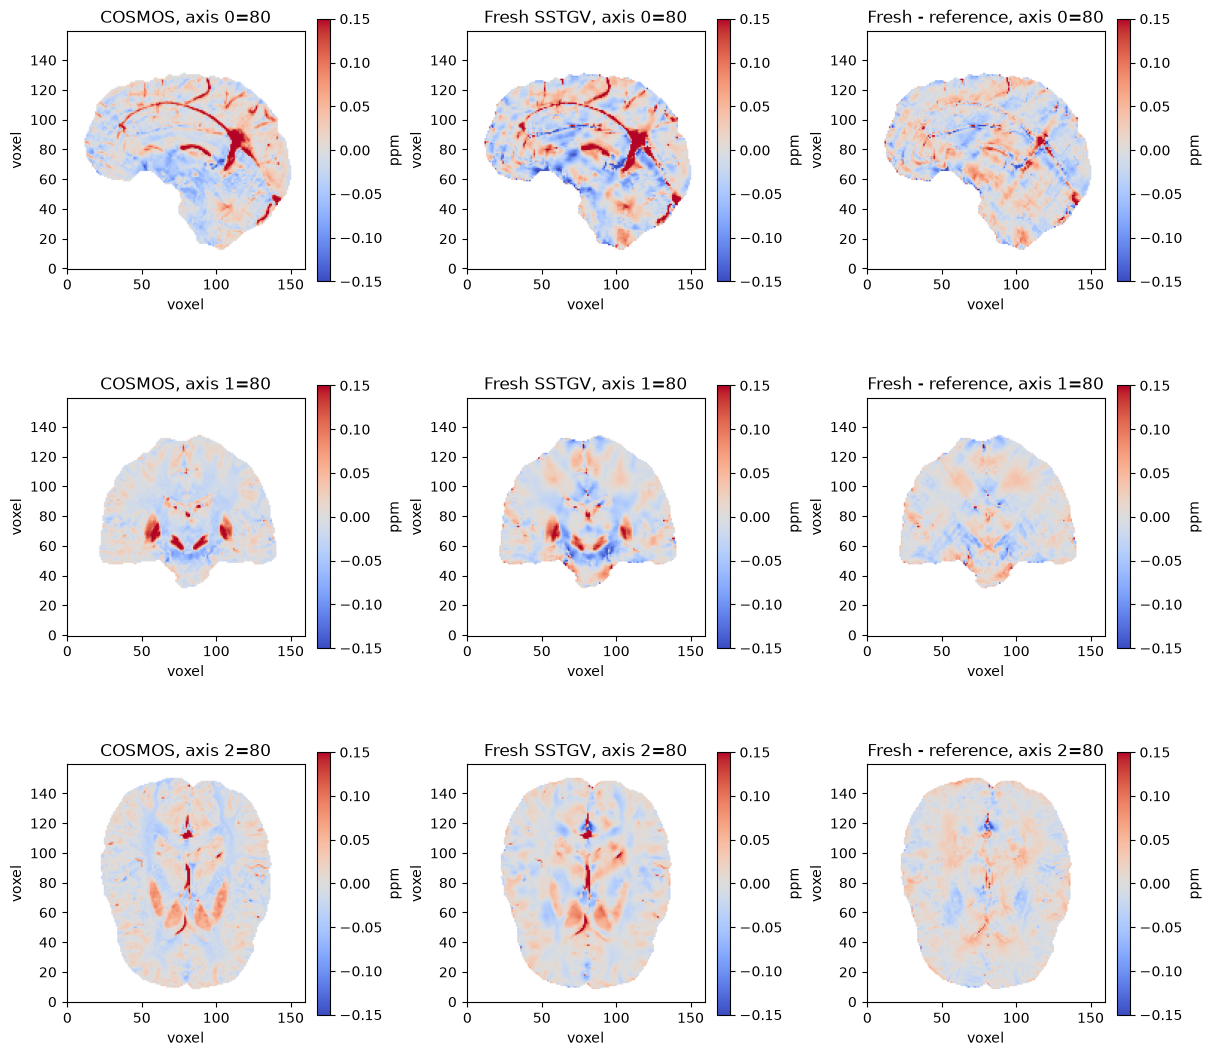

In [4]:
with np.load('notebooks/reference_outputs/independent_measurements.npz', allow_pickle=False) as z:
    cosmos, sti33 = z['cosmos'], z['sti33']
with np.load('notebooks/reference_outputs/canonical_tgv.npz', allow_pickle=False) as z:
    oracle_tgv, oracle_eta = z['reconstruction'], z['residual_phase']
with np.load('notebooks/reference_outputs/canonical_tv.npz', allow_pickle=False) as z:
    oracle_tv = z['reconstruction']
with np.load('notebooks/reference_outputs/original_canonical.npz', allow_pickle=False) as z:
    original_canonical = z['reconstruction']
with np.load('notebooks/reference_outputs/original_default.npz', allow_pickle=False) as z:
    original_default = z['reconstruction']
mask = observations['mask']
print("Fresh/C oracle max |chi| difference [ppm]:", np.max(abs(fresh_tgv-oracle_tgv)))
print("Fresh/C oracle max |eta| difference [rad]:", np.max(abs(tgv_info['residual_phase']-oracle_eta)))
rows=[]
for name, a in [('Original source defaults',original_default),('Original source, paper pair',original_canonical),('Corrected C TGV',oracle_tgv),('Fresh cleaned TGV',fresh_tgv),('Corrected C TV',oracle_tv),('Fresh cleaned TV',fresh_tv)]:
    row={'method':name,'COSMOS':metrics(a,cosmos,mask),'STI_chi33':metrics(a,sti33,mask)}
    rows.append(row)
lines=['| Method | COSMOS NCC | COSMOS range-NRMSE | COSMOS L2 error (%) | STI chi33 L2 error (%) |','|---|---:|---:|---:|---:|']
for r in rows:
    lines.append(f"| {r['method']} | {r['COSMOS']['ncc']:.6f} | {r['COSMOS']['nrmse']:.6f} | {100*r['COSMOS']['relative_l2']:.3f} | {100*r['STI_chi33']['relative_l2']:.3f} |")
display(Markdown(chr(10).join(lines)))
print("Fresh TGV observation metrics:",observation_metrics(fresh_tgv,tgv_info['residual_phase'],observations['phase'],mask,SPACING))
run=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True)
assert run.returncode == 0, run.stderr+Path('output/judge_report.json').read_text()
print(Path('output/judge_report.json').read_text())
reconstruction_figure(fresh_tgv,cosmos,mask)
plt.show()

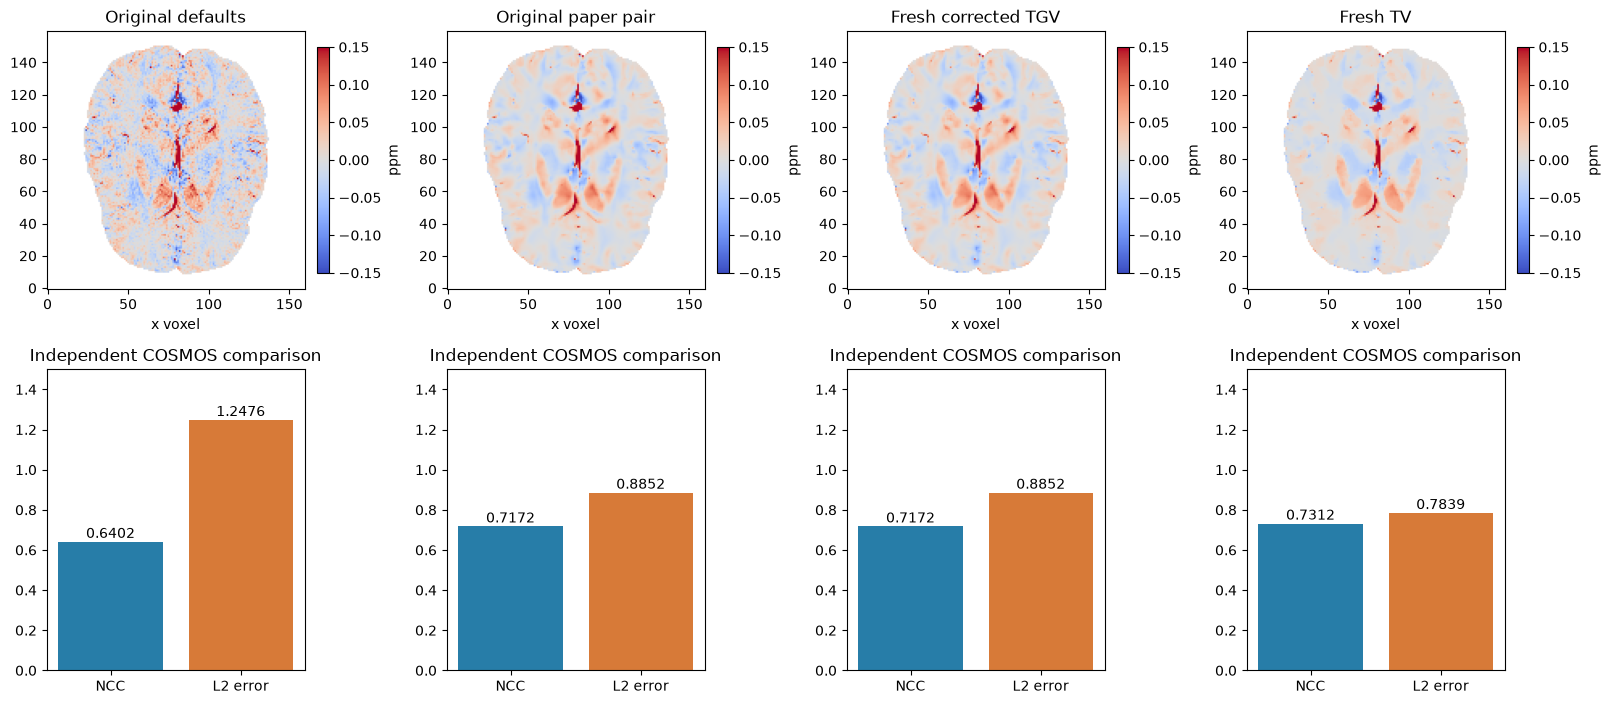

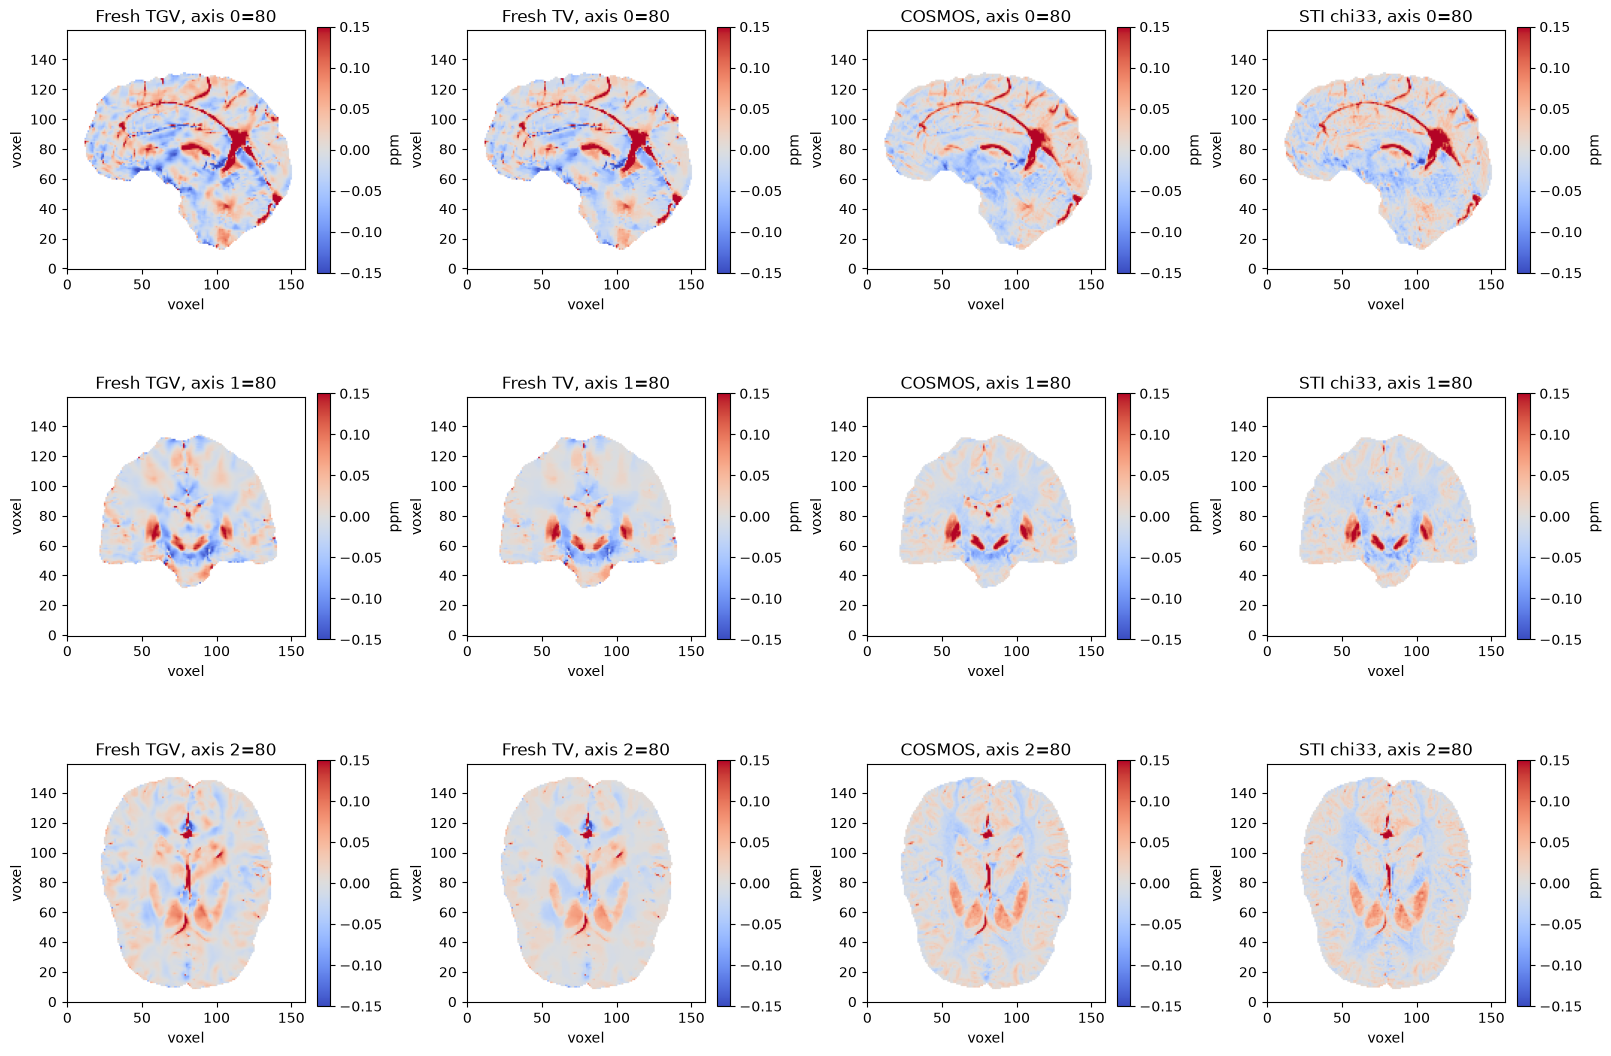

In [5]:
method_comparison_figure([original_default,original_canonical,fresh_tgv,fresh_tv],
    ['Original defaults','Original paper pair','Fresh corrected TGV','Fresh TV'],cosmos,mask)
plt.show()
fig,axs=plt.subplots(3,4,figsize=(16,11),constrained_layout=True)
for row,axis in enumerate(range(3)):
    for col,(a,name) in enumerate(zip([fresh_tgv,fresh_tv,cosmos,sti33],['Fresh TGV','Fresh TV','COSMOS','STI chi33'])):
        im=axs[row,col].imshow(np.take(np.where(mask,a,np.nan),80,axis=axis).T,origin='lower',cmap='coolwarm',vmin=-.15,vmax=.15)
        axs[row,col].set_title(f'{name}, axis {axis}=80')
        axs[row,col].set_xlabel('voxel');axs[row,col].set_ylabel('voxel')
        fig.colorbar(im,ax=axs[row,col],label='ppm',shrink=.7)
plt.show()

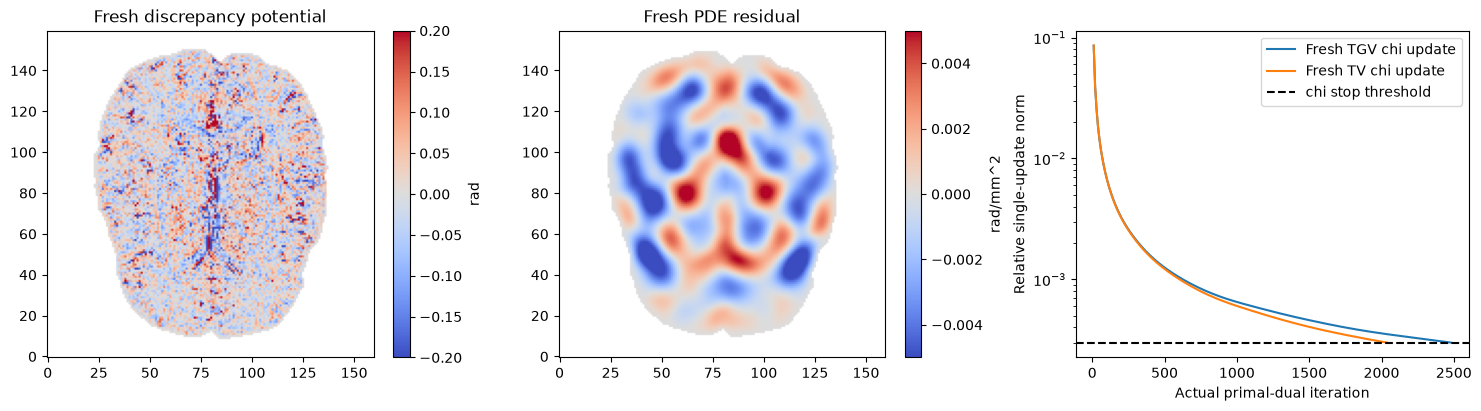

Fixed-mask mean chi [ppm]: -1.5223507189971734e-20 eta [rad]: -2.28352607849576e-20
Runtime and full-precision scientific measurements are displayed above; no reference snapshot is rewritten.


In [6]:
mi=interior_mask(mask)
constraint=laplacian(tgv_info['residual_phase'],SPACING)-wave_operator(fresh_tgv*PHASE_PER_PPM,SPACING)-wrapped_laplacian(observations['phase'],SPACING)
fig,axs=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
im=axs[0].imshow(np.where(mask[:,:,80],tgv_info['residual_phase'][:,:,80],np.nan).T,origin='lower',cmap='coolwarm',vmin=-.2,vmax=.2)
axs[0].set_title('Fresh discrepancy potential');fig.colorbar(im,ax=axs[0],label='rad')
im=axs[1].imshow(np.where(mi[:,:,80],constraint[:,:,80],np.nan).T,origin='lower',cmap='coolwarm',vmin=-.005,vmax=.005)
axs[1].set_title('Fresh PDE residual');fig.colorbar(im,ax=axs[1],label='rad/mm^2')
for info,name in [(tgv_info,'Fresh TGV'),(tv_info,'Fresh TV')]:
    history=info['history'];axs[2].semilogy(history[:,0],history[:,1],label=name+' chi update')
axs[2].axhline(3e-4,color='black',ls='--',label='chi stop threshold')
axs[2].set_xlabel('Actual primal-dual iteration');axs[2].set_ylabel('Relative single-update norm');axs[2].legend()
plt.show()
print('Fixed-mask mean chi [ppm]:',fresh_tgv[mask].mean(),'eta [rad]:',tgv_info['residual_phase'][mask].mean())
print('Runtime and full-precision scientific measurements are displayed above; no reference snapshot is rewritten.')

## 6. Conclusion

This notebook actively reconstructed the full real three-dimensional acquisition with local TGV and TV implementations, then evaluated the fresh joint susceptibility/discrepancy output. The separate original-default, original paper-parameter and corrected-source measurements identify where parameter changes and the anisotropic-adjoint correction enter the comparison. Full-state numerical parity and independent operator/PDE checks address different questions from similarity to multi-orientation measurements.

**TGV is not better than TV on the chosen whole-brain COSMOS/STI error measures.** Both retain meaningful brain structures and venous contrast, but differences around the inferior frontal regions and other boundaries remain. The selected paper's phantom/EPI demonstrations are not reproduced by reusing its claims on this distinct Wave-CAIPI measurement. The real challenge reported whole-volume L2-percent errors from 69.0% to 140.9%, median 83.9%, with GRAZ TGV around 77.5%; those are historical results using different parameter/implementation choices and cannot be relabeled this task's measurements. The challenge itself discusses bias from the LBV-plus-polynomial phase-processing pipeline used for multi-orientation references.

The benchmark tests a research-scale single-step inverse implementation. It does not claim exact biological susceptibility truth, establish superiority over other methods, recover an identifiable background phase, or reproduce a published leaderboard rank. The fixed gauge, physical scale, acquisition support and comparison formulas are shared by plots, notebook metrics and the independent Judge; the source arrays and upstream measurements remain separately identified in `test/validation.md`.


The auxiliary residual-phase potential is not a recovered background phase. COSMOS and STI chi33 are independent reconstructed measurements with different physical meanings. The PDE, residual and regularization comparisons test the scalar single-step model, without treating anisotropic human tissue as exact scalar truth.
